# Task 2 – Price prediction (Regression)
We train and tune five models: **Linear Regression, Decision Tree, Random Forest, SVR, MLP**,
evaluate them with MAE, MSE, RMSE and R², and save the best one for the API.

⏱ The grid searches take about 5 minutes in total.

In [1]:
import sys, json, time, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from common import (load_raw, clean_rows, make_preprocessor, NUMERIC, CATEGORICAL, MIN_PLAUSIBLE_PRICE,
                    RANDOM_STATE, TEST_SIZE, FIG_DIR, RES_DIR, MODEL_DIR)

sns.set_theme(style="whitegrid")
for d in (FIG_DIR, RES_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Prepare the data
**Decision on Price = 0:** these are "Negotiable" ads that have *no price*. Zero is not a real price, it is a
missing target, so we cannot train or evaluate on them → we remove them. Prices below 5,000 SAR are monthly
instalments → also removed.

**Input features:** all descriptive features (Year, Engine_Size, Mileage, Make, Type, Origin, Color, Options,
Fuel_Type, Gear_Type, Region) because each showed some relationship with price in the EDA.
`Negotiable` is left out: after removing unpriced ads it is always False.

In [2]:
df = clean_rows(load_raw())
print("Rows after cleaning:", len(df))
print("Price = 0:", (df.Price == 0).sum(), "| 0 < Price < 5000:", ((df.Price > 0) & (df.Price < MIN_PLAUSIBLE_PRICE)).sum())
df = df[df.Price >= MIN_PLAUSIBLE_PRICE].reset_index(drop=True)
print("Rows used for regression:", len(df))

FEATURES = NUMERIC + CATEGORICAL
X, y = df[FEATURES], df["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Rows after cleaning: 8179
Price = 0: 2586 | 0 < Price < 5000: 96
Rows used for regression: 5497
Train: (4397, 11)  Test: (1100, 11)


## 2. Pipeline
Each model = preprocessing (engine-size imputation by car model → median imputation → scaling → one-hot encoding,
rare categories grouped) + the estimator. The model learns **log(1 + Price)** because price is very skewed;
`TransformedTargetRegressor` converts predictions back to SAR automatically.

In [3]:
def make_model(estimator):
    pipe = Pipeline([("prep", make_preprocessor(NUMERIC, CATEGORICAL)), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

make_model(LinearRegression())

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...egression())])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('engine_imputer', ...), ('columns', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipe

## 3. Models and hyperparameter grids

In [4]:
R = "regressor__"
MINF = R + "prep__columns__cat__onehot__min_frequency"
models = {
    "Linear Regression": (LinearRegression(), {
        MINF: [1, 5, 10, 20], R + "model__fit_intercept": [True, False]}),
    "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE), {
        R + "model__max_depth": [10, 15, 20, None],
        R + "model__min_samples_leaf": [1, 3, 5, 10]}),
    "Random Forest": (RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), {
        R + "model__max_depth": [20, None],
        R + "model__min_samples_leaf": [1, 2],
        R + "model__max_features": [0.3, 0.6, 1.0]}),
    "SVR": (SVR(kernel="rbf"), {
        R + "model__C": [0.3, 1, 3, 10, 100],
        R + "model__epsilon": [0.05, 0.1],
        R + "model__gamma": ["scale", 0.01]}),
    "MLP": (MLPRegressor(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE), {
        R + "model__hidden_layer_sizes": [(64,), (128, 64), (64, 32)],
        R + "model__alpha": [1e-4, 1e-3, 1e-2],
        R + "model__learning_rate_init": [1e-3, 5e-3]}),
}

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred), "MAPE_%": np.mean(np.abs(y_true - y_pred) / y_true) * 100}

## 4. Grid search with 5-fold cross-validation (scoring = MAE)

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted, preds = [], {}, {}

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
rows.append({"model": "Baseline (median)", "cv_MAE": np.nan, "best_params": "-",
             **metrics(y_test, baseline.predict(X_test))})

for name, (est, grid) in models.items():
    t0 = time.time()
    gs = GridSearchCV(make_model(est), grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    preds[name] = gs.best_estimator_.predict(X_test)
    params = {k.replace(R, "").replace("model__", ""): v for k, v in gs.best_params_.items()}
    rows.append({"model": name, "cv_MAE": -gs.best_score_, "best_params": params,
                 **metrics(y_test, preds[name]),
                 "train_R2": r2_score(y_train, gs.best_estimator_.predict(X_train))})
    print(f"{name:18s} done in {time.time() - t0:5.0f}s  best params: {params}")

Linear Regression  done in    30s  best params: {'fit_intercept': True, 'prep__columns__cat__onehot__min_frequency': 1}
Decision Tree      done in     4s  best params: {'max_depth': 15, 'min_samples_leaf': 3}
Random Forest      done in    93s  best params: {'max_depth': None, 'max_features': 0.3, 'min_samples_leaf': 1}
SVR                done in    76s  best params: {'C': 1, 'epsilon': 0.05, 'gamma': 'scale'}
MLP                done in    70s  best params: {'alpha': 0.01, 'hidden_layer_sizes': (64,), 'learning_rate_init': 0.001}


## 5. Results

In [6]:
results = pd.DataFrame(rows)
results.to_csv(RES_DIR / "regression_results.csv", index=False)
results.drop(columns="best_params").round(3)

,model,cv_MAE,MAE,MSE,RMSE,R2,MAPE_%,train_R2
0,Baseline (median),NaN,43420.637,5.486672e+09,74072.072,-0.072,75.359,NaN
1,Linear Regression,16055.249,14799.259,9.942401e+08,31531.573,0.806,21.100,0.860
2,Decision Tree,21981.543,19812.920,1.440276e+09,37950.968,0.719,29.535,0.884
3,Random Forest,15794.506,14975.081,1.097049e+09,33121.731,0.786,20.989,0.944
4,SVR,13767.645,13273.554,8.999689e+08,29999.482,0.824,18.035,0.881
5,MLP,15560.152,15367.036,1.187434e+09,34459.160,0.768,20.567,0.785


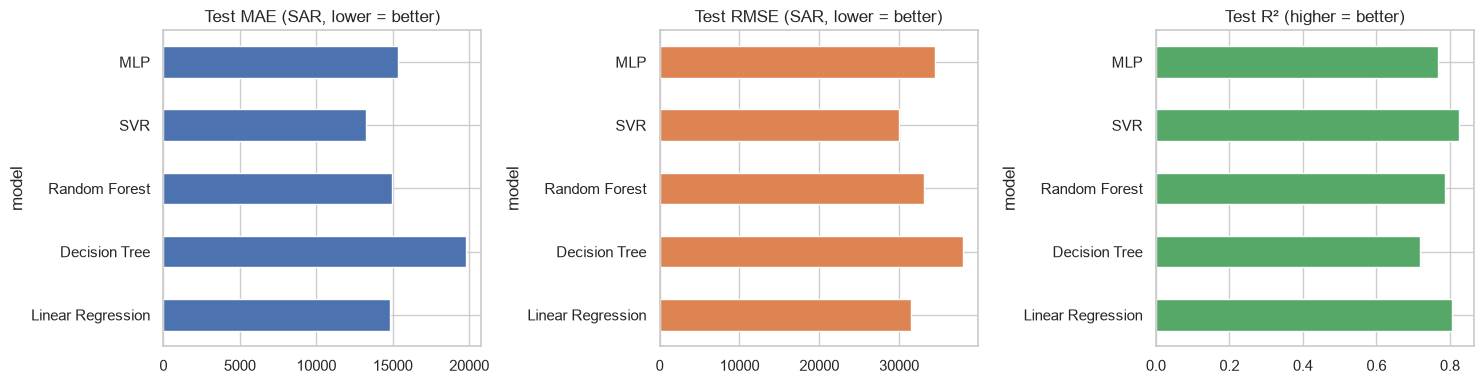

In [7]:
plot = results[results.model != "Baseline (median)"].set_index("model")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
plot["MAE"].plot.barh(ax=ax[0], color="#4C72B0", title="Test MAE (SAR, lower = better)")
plot["RMSE"].plot.barh(ax=ax[1], color="#DD8452", title="Test RMSE (SAR, lower = better)")
plot["R2"].plot.barh(ax=ax[2], color="#55A868", title="Test R² (higher = better)")
plt.tight_layout(); plt.savefig(FIG_DIR / "11_regression_comparison.png", dpi=130); plt.show()

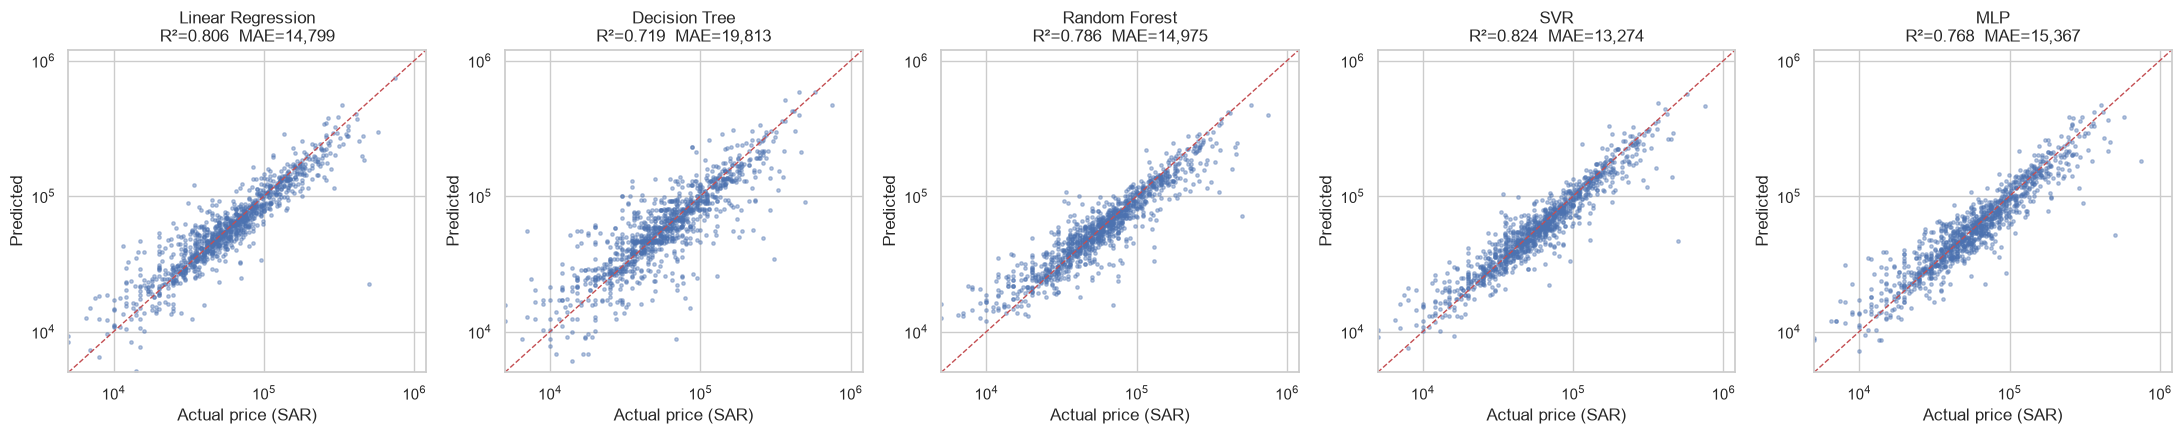

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for a, (name, p) in zip(axes, preds.items()):
    a.scatter(y_test, p, s=6, alpha=0.4)
    lim = [5e3, 1.2e6]
    a.plot(lim, lim, "r--", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_xlim(lim); a.set_ylim(lim)
    a.set_title(f"{name}\nR²={r2_score(y_test, p):.3f}  MAE={mean_absolute_error(y_test, p):,.0f}")
    a.set_xlabel("Actual price (SAR)"); a.set_ylabel("Predicted")
plt.tight_layout(); plt.savefig(FIG_DIR / "10_regression_pred_vs_actual.png", dpi=130); plt.show()

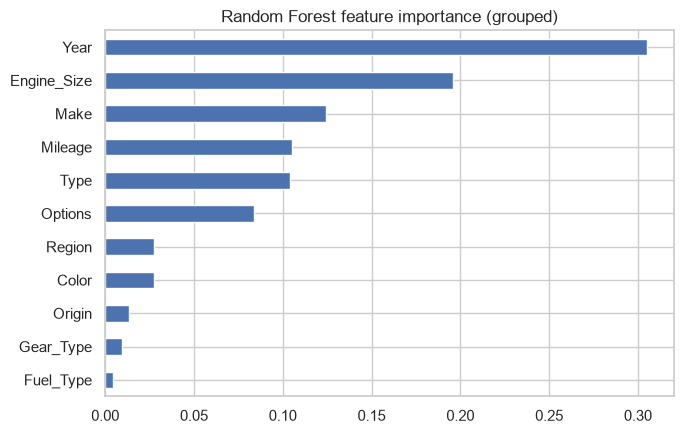

In [9]:
# Feature importance of the Random Forest, summed back to the original columns
rf = fitted["Random Forest"].regressor_
names = rf.named_steps["prep"].named_steps["columns"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names)
imp = imp.groupby(lambda n: next(f for f in FEATURES if n.split("__", 1)[1].startswith(f))).sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5))
imp.plot.barh(ax=ax, color="#4C72B0", title="Random Forest feature importance (grouped)")
plt.tight_layout(); plt.savefig(FIG_DIR / "12_regression_feature_importance.png", dpi=130); plt.show()

## 6. Choose and save the best model
We choose by the **cross-validation** MAE (not the test set), then report its test scores.

In [10]:
best_name = results.dropna(subset=["cv_MAE"]).sort_values("cv_MAE").iloc[0]["model"]
best = fitted[best_name]
joblib.dump(best, MODEL_DIR / "best_regressor.joblib")
json.dump({"model": best_name, "features": FEATURES,
           "test_metrics": {k: float(v) for k, v in metrics(y_test, preds[best_name]).items()}},
          open(MODEL_DIR / "best_regressor.json", "w"), indent=2)
print("Best model:", best_name)
print({k: round(float(v), 3) for k, v in metrics(y_test, preds[best_name]).items()})

Best model: SVR
{'MAE': 13273.554, 'MSE': 899968914.853, 'RMSE': 29999.482, 'R2': 0.824, 'MAPE_%': 18.035}


**Why this model?** After one-hot encoding the data has many sparse columns, and log-price is close to a smooth
function of them. SVR with an RBF kernel fits that smooth surface and its ε-tube ignores small noise. Linear
Regression is close behind because depreciation is roughly linear in log space. Random Forest overfits
(train R² ≫ test R²) and cannot extrapolate to the most expensive cars; the single tree has the highest variance.

## 7. Error analysis

In [11]:
err = X_test.copy()
err["Actual"] = y_test
err["Predicted"] = preds[best_name].round(0)
err["AbsError"] = (err.Actual - err.Predicted).abs()
err["PctError"] = err.AbsError / err.Actual * 100

err["price_band"] = pd.cut(err.Actual, [0, 30e3, 60e3, 100e3, 200e3, 2e6],
                           labels=["<30k", "30-60k", "60-100k", "100-200k", ">200k"])
err.groupby("price_band", observed=True).agg(n=("Actual", "size"), MAE=("AbsError", "mean"),
                                             median_pct_error=("PctError", "median")).round(1)

,n,MAE,median_pct_error
price_band,,,
<30k,215,4833.7,16.6
30-60k,381,7294.0,11.3
60-100k,262,11270.6,11.4
100-200k,178,20238.8,9.2
>200k,64,66050.5,15.5


In [12]:
# Are rare car models harder?
counts = X_train.Type.value_counts()
err["type_freq_in_train"] = err.Type.map(counts).fillna(0)
err["type_bucket"] = pd.cut(err.type_freq_in_train, [-1, 9, 30, 100, 1e5],
                            labels=["<10 (rare)", "10-30", "31-100", ">100"])
err.groupby("type_bucket", observed=True).agg(n=("Actual", "size"), MAE=("AbsError", "mean"),
                                              median_pct_error=("PctError", "median")).round(1)

,n,MAE,median_pct_error
type_bucket,,,
<10 (rare),189,23963.9,22.3
10-30,236,11082.7,12.4
31-100,375,13745.8,11.3
>100,300,7671.8,8.7


In [13]:
# The worst predictions
err.sort_values("AbsError", ascending=False).head(8)[["Make", "Type", "Year", "Mileage", "Actual", "Predicted", "PctError"]].round(0)

,Make,Type,Year,Mileage,Actual,Predicted,PctError
2722,Rolls-Royce,Camargue,1990,5000.0,500000,46877.0,91.0
339,Lexus,LX,2020,455000.0,455000,139025.0,69.0
787,Bentley,Bentayga,2018,26000.0,750000,463902.0,38.0
254,Lexus,LX,2018,105000.0,355000,160576.0,55.0
308,Rolls-Royce,Ghost,2010,175000.0,310000,117110.0,62.0
4713,Land Rover,Defender,2021,100.0,450000,264951.0,41.0
3429,BMW,X,2020,2300.0,465000,293319.0,37.0
2439,Land Rover,Range Rover,2020,17000.0,428000,263566.0,38.0


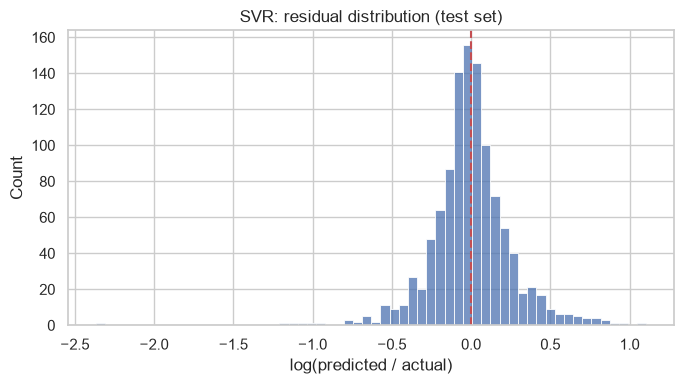

In [14]:
plt.figure(figsize=(7, 4))
sns.histplot(np.log(err.Predicted / err.Actual), bins=60)
plt.axvline(0, color="r", ls="--"); plt.xlabel("log(predicted / actual)")
plt.title(f"{best_name}: residual distribution (test set)")
plt.tight_layout(); plt.savefig(FIG_DIR / "13_regression_residuals.png", dpi=130); plt.show()

**Error analysis findings**
- Rare car models (seen < 10 times in training) have about 3× the relative error of common ones: the encoder groups
  them as "infrequent", so the model only knows their make, year and engine.
- The largest absolute errors are luxury cars above 200k SAR (few training examples), e.g. a 1990 Rolls-Royce
  classic that gained value with age.
- Some errors come from bad data, e.g. a 2020 Lexus LX with Mileage = Price = 455,000 (a typing error).